In [147]:
import read_data
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, fbeta_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    fbeta_score,
    mean_squared_error,
    roc_auc_score,
    average_precision_score
)

In [148]:
import importlib
import read_data

importlib.reload(read_data)

<module 'read_data' from 'c:\\Users\\utente\\Documents\\GitHub\\FYS-STK3155--Project3--UiO\\code\\read_data.py'>

In [37]:
print(read_data.evaluate)

<function evaluate at 0x00000193951A6FC0>


In [ ]:
X_events, y = read_data.ImportTrainingData()
X = read_data.aggregate(X_events)

In [16]:
X = read_data.aggregate(X_events)

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # stratify to split successes evenly, since we have so few
)

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

In [33]:
limit = np.finfo(np.float32).max

for name, data in [("train", X_train), ("test", X_test)]: # Given by Chat, some values were too big
    numeric = data.select_dtypes(include=np.number)

    print(f"\n{name}:")
    print("Infinite values:", np.isinf(numeric).sum().sum())

    large = numeric.columns[(numeric.abs() > limit).any()]
    print("Columns with excessively large values:", large.tolist())


train:
Infinite values: 0
Columns with excessively large values: []

test:
Infinite values: 0
Columns with excessively large values: []


In [34]:
model = XGBClassifier()
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [35]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.01).astype(int)


In [38]:
thresholds = [0.01, 0.025, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    print(threshold, read_data.evaluate(model, X_test, y_test, threshold))

0.01 0.015881490148603915
0.025 0.018287776534756023
0.05 0.032244237574438256
0.1 0.031281723019977406
0.15 0.03031920846551657
0.2 0.02839417935659488
0.3 0.03970372537150979
0.4 0.07796367891132833
0.5 0.07796367891132833


In [39]:
thresholds = [0.002, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02]

for threshold in thresholds:
    print(threshold, read_data.evaluate(model, X_test, y_test, threshold))

0.002 0.01798152190379121
0.005 0.018949505290947855
0.0075 0.016964319022372366
0.01 0.015881490148603915
0.0125 0.015340075711719692
0.015 0.01670650262385607
0.02 0.018769033811986444


In [56]:
y_pred = (y_prob >= 0.01).astype(int) # Seems low, but almost necessary to not get too high FNR
print(sum(y_prob))
print(sum(y_pred))
print(sum(y_test))

4.5534325
36
13


In [57]:
read_data.evaluate(model, X_test, y_test, 0.01)

0.015881490148603915

In [58]:
for X, y in [(X_train, y_train), (X_test, y_test)]:
    prob = model.predict_proba(X)[:, 1]
    pred = model.predict(X)

    mse = mean_squared_error(y, prob)
    f2 = fbeta_score(y, pred, beta=2, zero_division=0)

    print(f"MSE: {mse:.4f}, F2: {f2:.4f}, Loss: {mse/f2 if f2 else float('inf'):.4f}")

MSE: 0.0000, F2: 1.0000, Loss: 0.0000
MSE: 0.0072, F2: 0.0926, Loss: 0.0780


In [59]:
trees = model.get_booster().trees_to_dataframe()
print(trees.groupby("Tree")["Node"].count().describe())

count       100.0
mean        11.06
std      8.955355
min           3.0
25%           5.0
50%           7.0
75%          13.0
max          43.0
Name: Node, dtype: Float64


Testing different models

In [60]:
loss_per_depth = []

for d in range(2, 20):
    model_d = XGBClassifier(max_depth=d, n_estimators=100)
    model_d.fit(X_train, y_train)

    print(f"Depth {d}: ", end="")
    loss_per_depth.append(read_data.evaluate(model_d, X_test, y_test))
print(loss_per_depth)


Depth 2: Depth 3: Depth 4: Depth 5: Depth 6: Depth 7: Depth 8: Depth 9: Depth 10: Depth 11: Depth 12: Depth 13: Depth 14: Depth 15: Depth 16: Depth 17: Depth 18: Depth 19: [0.01990757721941918, 0.019473395217210053, 0.015840996243059634, 0.01862275770732335, 0.015881490148603915, 0.019051876717380116, 0.016832405934110284, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433, 0.016354699269868433]


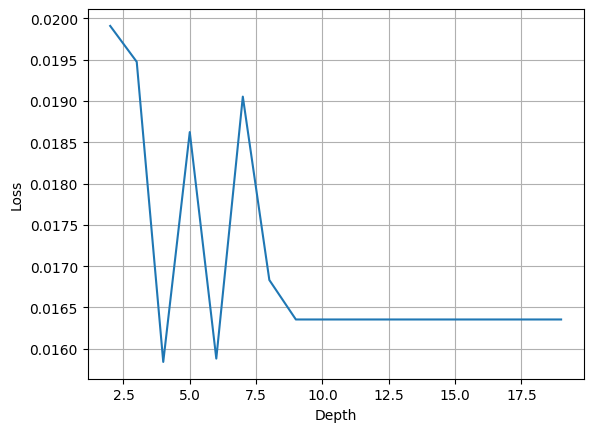

In [61]:
plt.plot(range(2, 20), loss_per_depth)
plt.xlabel("Depth")
plt.ylabel("Cost")
plt.grid()
plt.show() # ealy values not shown as depth three gives infinate loss, which breaks continuity

Best depth 4, but will cross validate later

In [62]:
trees = model.get_booster().trees_to_dataframe()
print(trees.groupby("Tree")["Node"].count().describe())

count       100.0
mean        11.06
std      8.955355
min           3.0
25%           5.0
50%           7.0
75%          13.0
max          43.0
Name: Node, dtype: Float64


In [65]:
loss_per_weight = []

for w in range(1, 100, 5):
    model_w = XGBClassifier(max_depth=4, n_estimators=100, scale_pos_weight=w)
    model_w.fit(X_train, y_train)

    print(f"Weight {w}: ", end="")
    loss_per_weight.append(read_data.evaluate(model_w, X_test, y_test))
print(loss_per_weight)

Weight 1: Weight 6: Weight 11: Weight 16: Weight 21: Weight 26: Weight 31: Weight 36: Weight 41: Weight 46: Weight 51: Weight 56: Weight 61: Weight 66: Weight 71: Weight 76: Weight 81: Weight 86: Weight 91: Weight 96: [0.015840996243059634, 0.017557523865252733, 0.021010388380714826, 0.01995729420866285, 0.01664699544198811, 0.0174942767014727, 0.019872596149798482, 0.01959200946148485, 0.02003181534819305, 0.024251341952809265, 0.020429641124792397, 0.017561347968876363, 0.019429363263770937, 0.02235262654721737, 0.018489558482542634, 0.02000164883211255, 0.020423766458407044, 0.022694030497223138, 0.016119072834650677, 0.02219904016237706]


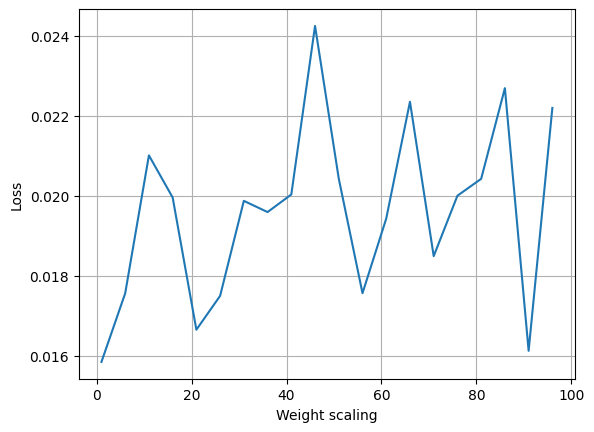

In [66]:
plt.plot(range(1,100,5), loss_per_weight)
plt.xlabel("Weight scaling")
plt.ylabel("Cost")
plt.grid()
plt.show()

Let us try 20 and test more after with cross validation

In [67]:
print(min(loss_per_weight))
loss_per_weight.index(min(loss_per_weight))

0.015840996243059634


0

In [89]:
loss_per_tree = []

for t in range(10, 500, 50):
    model_t = XGBClassifier(max_depth=4, n_estimators=t, scale_pos_weight=20)
    model_t.fit(X_train, y_train)

    print(f"Trees {t}: ", end="")
    loss_per_tree.append(read_data.evaluate(model_t, X_test, y_test))
print(loss_per_tree)

Trees 10: Trees 60: Trees 110: Trees 160: Trees 210: Trees 260: Trees 310: Trees 360: Trees 410: Trees 460: [0.0996897766874595, 0.017712685104925185, 0.017008907871786504, 0.016633615968748926, 0.01668440152425319, 0.0166072663734667, 0.016444215923547747, 0.01655740784481168, 0.016474740020930766, 0.015947158006019892]


In [94]:
print(min(loss_per_tree))
print(loss_per_tree.index(min(loss_per_tree))*50 + 10)

0.02293020924553275
460


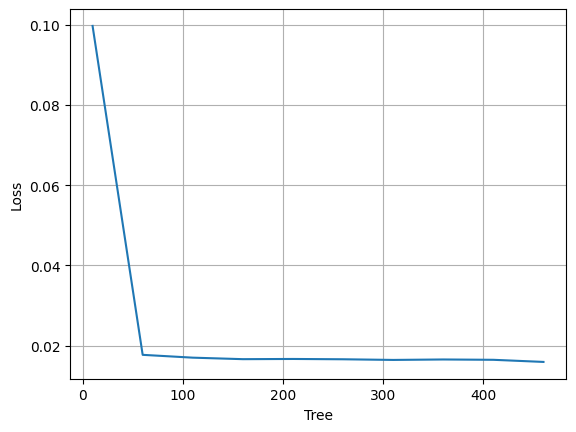

In [91]:
plt.plot(range(10, 500, 50), loss_per_tree)
plt.xlabel("Tree")
plt.ylabel("Cost")
plt.grid()
plt.show()

Struggle to overfit

In [92]:
loss_per_tree = []

for t in range(0, 50, 5): # more accurate
    model_t = XGBClassifier(max_depth=4, n_estimators=t, scale_pos_weight=36)
    model_t.fit(X_train, y_train)

    print(f"Trees {t}: ", end="")
    loss_per_tree.append(read_data.evaluate(model_t, X_test, y_test))
print(loss_per_tree)

Trees 0: Trees 5: Trees 10: Trees 15: Trees 20: Trees 25: Trees 30: Trees 35: Trees 40: Trees 45: [10.148505947681574, 0.5700829297304154, 0.40620734651501367, 0.05434072432531552, 0.031125149842013013, 0.03049126157744063, 0.02948835953138769, 0.026237761625088753, 0.02435425689909607, 0.02293020924553275]


In [95]:
print(min(loss_per_tree))
print(loss_per_tree.index(min(loss_per_tree))*5)

0.02293020924553275
45


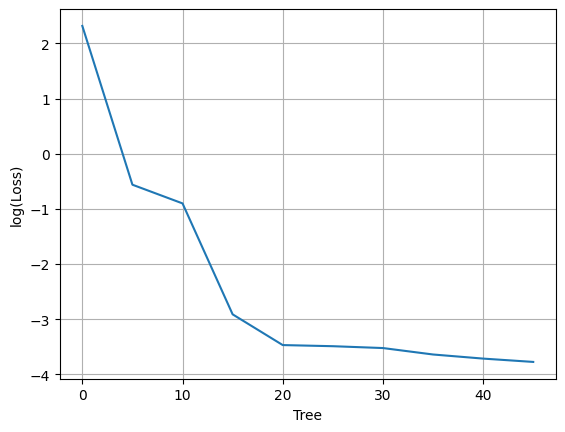

In [99]:
plt.plot(range(0, 50, 5), np.log(loss_per_tree))
plt.xlabel("Tree")
plt.ylabel("log(Cost)")
plt.grid()
plt.show() # ealy values not shown as depth three gives infinate loss, which breaks continuity

It gets more and more accurate, but not really a noticable difference after

In [103]:
# Written by ChatGPT, slightly adjusted
weights = range(1, 401, 5)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

costs_list = []
f2s_zeros = []

for weight in weights:
    costs, f2s = [], []

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_val = X_val.replace([np.inf, -np.inf], np.nan)

        model = XGBClassifier(
            max_depth=4,
            n_estimators=20,
            scale_pos_weight=weight,
            random_state=42
        )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.01).astype(int)

        mse = mean_squared_error(y_val, probabilities)
        f2 = fbeta_score(y_val, predictions, beta=2, zero_division=0)

        f2s.append(f2)
        costs.append(mse / f2 if f2 > 0 else float("inf"))

    mean_cost = np.mean(costs)
    zero_count = sum(f == 0 for f in f2s)

    print(
        f"Weight: {weight:3} | "
        f"Cost: {mean_cost:.5f} | "
        f"Zero F2: {zero_count}/5"
    )

    costs_list.append(mean_cost)
    f2s_zeros.append(zero_count)

valid = [i for i, zeros in enumerate(f2s_zeros) if zeros == 0]

if valid:
    best = min(valid, key=lambda i: costs_list[i])
    print(f"\nBest weight: {best + 1}")
    print(f"Custom cost: {costs_list[best]:.5f}")
else:
    print("\nNo weights achieved non-zero F2 in all folds.")

Weight:   1 | Cost: 0.02412 | Zero F2: 0/5
Weight:   6 | Cost: inf | Zero F2: 1/5
Weight:  11 | Cost: inf | Zero F2: 1/5
Weight:  16 | Cost: inf | Zero F2: 1/5
Weight:  21 | Cost: inf | Zero F2: 1/5
Weight:  26 | Cost: inf | Zero F2: 1/5
Weight:  31 | Cost: inf | Zero F2: 1/5
Weight:  36 | Cost: 0.03235 | Zero F2: 0/5
Weight:  41 | Cost: 0.03311 | Zero F2: 0/5
Weight:  46 | Cost: 0.03588 | Zero F2: 0/5
Weight:  51 | Cost: 0.03546 | Zero F2: 0/5
Weight:  56 | Cost: 0.03680 | Zero F2: 0/5
Weight:  61 | Cost: 0.03679 | Zero F2: 0/5
Weight:  66 | Cost: 0.03615 | Zero F2: 0/5
Weight:  71 | Cost: 0.03529 | Zero F2: 0/5
Weight:  76 | Cost: 0.03681 | Zero F2: 0/5
Weight:  81 | Cost: 0.03557 | Zero F2: 0/5
Weight:  86 | Cost: 0.03629 | Zero F2: 0/5
Weight:  91 | Cost: 0.03595 | Zero F2: 0/5
Weight:  96 | Cost: 0.03975 | Zero F2: 0/5
Weight: 101 | Cost: 0.03499 | Zero F2: 0/5
Weight: 106 | Cost: 0.03645 | Zero F2: 0/5
Weight: 111 | Cost: 0.03580 | Zero F2: 0/5
Weight: 116 | Cost: 0.03898 | Zero 

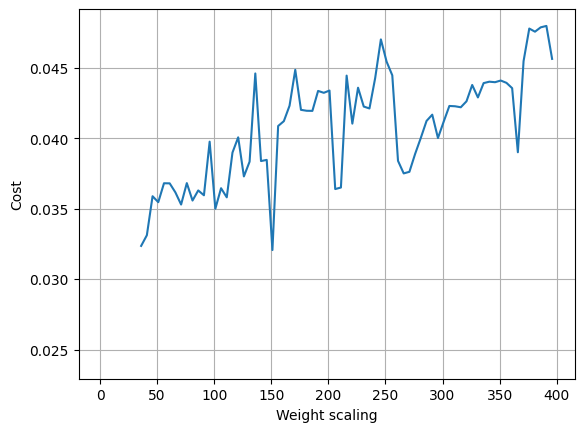

In [105]:
plt.plot(weights, costs_list)
plt.xlabel("Weight scaling")
plt.ylabel("Cost")
plt.grid()
plt.show()

In [107]:
# Written by ChatGPT, slightly adjusted
weights = [1, 1.25, 1.5, 1.75, 2, 2.5, 3, 3.5, 4, 4.5, 5]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

costs_list = []
f2s_zeros = []

for weight in weights:
    costs, f2s = [], []

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_val = X_val.replace([np.inf, -np.inf], np.nan)

        model = XGBClassifier(
            max_depth=4,
            n_estimators=20,
            scale_pos_weight=weight,
            random_state=42
        )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.01).astype(int)

        mse = mean_squared_error(y_val, probabilities)
        f2 = fbeta_score(y_val, predictions, beta=2, zero_division=0)

        f2s.append(f2)
        costs.append(mse / f2 if f2 > 0 else float("inf"))

    mean_cost = np.mean(costs)
    zero_count = sum(f == 0 for f in f2s)

    print(
        f"Weight: {weight:3} | "
        f"Cost: {mean_cost:.5f} | "
        f"Zero F2: {zero_count}/5"
    )

    costs_list.append(mean_cost)
    f2s_zeros.append(zero_count)

valid = [i for i, zeros in enumerate(f2s_zeros) if zeros == 0]

if valid:
    best = min(valid, key=lambda i: costs_list[i])
    print(f"\nBest weight: {best + 1}")
    print(f"Custom cost: {costs_list[best]:.5f}")
else:
    print("\nNo weights achieved non-zero F2 in all folds.")

Weight:   1 | Cost: 0.02412 | Zero F2: 0/5
Weight: 1.25 | Cost: inf | Zero F2: 1/5
Weight: 1.5 | Cost: inf | Zero F2: 2/5
Weight: 1.75 | Cost: inf | Zero F2: 2/5
Weight:   2 | Cost: inf | Zero F2: 2/5
Weight: 2.5 | Cost: inf | Zero F2: 2/5
Weight:   3 | Cost: inf | Zero F2: 2/5
Weight: 3.5 | Cost: inf | Zero F2: 2/5
Weight:   4 | Cost: inf | Zero F2: 2/5
Weight: 4.5 | Cost: inf | Zero F2: 2/5
Weight:   5 | Cost: inf | Zero F2: 2/5

Best weight: 1
Custom cost: 0.02412


Seems like no sclaing is the best scaling in this case, maybe the model already finds enough positives

In [108]:
# By ChatGPT

params = {
    "reg_lambda": [0.1, 1, 5, 10, 20],
    "reg_alpha": [0, 0.01, 0.1, 1, 10],
    "gamma": [0, 0.01, 0.1, 0.5, 1]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}

for param, values in params.items():
    results[param] = []

    for value in values:
        costs = []
        zero_f2 = 0

        for train_idx, val_idx in cv.split(X, y):
            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

            X_train = X_train.replace([np.inf, -np.inf], np.nan)
            X_val = X_val.replace([np.inf, -np.inf], np.nan)

            model = XGBClassifier(
                max_depth=4,
                n_estimators=20,
                scale_pos_weight=1,
                random_state=42,
                **{param: value}
            )

            model.fit(X_train, y_train)

            probabilities = model.predict_proba(X_val)[:, 1]
            predictions = (probabilities >= 0.01).astype(int)

            mse = mean_squared_error(y_val, probabilities)
            f2 = fbeta_score(y_val, predictions, beta=2, zero_division=0)

            if f2 == 0:
                zero_f2 += 1
                costs.append(float("inf"))
            else:
                costs.append(mse / f2)

        mean_cost = np.mean(costs)

        results[param].append((value, mean_cost, zero_f2))

        print(
            f"{param}: {value:5} | "
            f"Cost: {mean_cost:.5f} | "
            f"Zero F2: {zero_f2}/5"
        )

    valid = [r for r in results[param] if r[2] == 0]

    if valid:
        best = min(valid, key=lambda r: r[1])
        print(f"Best {param}: {best[0]} | Cost: {best[1]:.5f}\n")
    else:
        print(f"No valid values for {param}\n")

reg_lambda:   0.1 | Cost: inf | Zero F2: 1/5
reg_lambda:     1 | Cost: 0.02412 | Zero F2: 0/5
reg_lambda:     5 | Cost: 0.02940 | Zero F2: 0/5
reg_lambda:    10 | Cost: 0.03068 | Zero F2: 0/5
reg_lambda:    20 | Cost: 0.04133 | Zero F2: 0/5
Best reg_lambda: 1 | Cost: 0.02412

reg_alpha:     0 | Cost: 0.02412 | Zero F2: 0/5
reg_alpha:  0.01 | Cost: 0.02114 | Zero F2: 0/5
reg_alpha:   0.1 | Cost: 0.02196 | Zero F2: 0/5
reg_alpha:     1 | Cost: 0.02644 | Zero F2: 0/5
reg_alpha:    10 | Cost: inf | Zero F2: 5/5
Best reg_alpha: 0.01 | Cost: 0.02114

gamma:     0 | Cost: 0.02412 | Zero F2: 0/5
gamma:  0.01 | Cost: 0.02412 | Zero F2: 0/5
gamma:   0.1 | Cost: 0.02496 | Zero F2: 0/5
gamma:   0.5 | Cost: 0.02629 | Zero F2: 0/5
gamma:     1 | Cost: 0.02928 | Zero F2: 0/5
Best gamma: 0 | Cost: 0.02412



In [109]:
# Written by ChatGPT
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

n_estimators_values = [20, 40, 60, 80, 100, 150, 200, 300]

for n in n_estimators_values:
    costs = []

    for train_idx, val_idx in cv.split(X, y):
        X_train_cv = X.iloc[train_idx].replace([np.inf, -np.inf], np.nan)
        X_val_cv = X.iloc[val_idx].replace([np.inf, -np.inf], np.nan)
        y_train_cv = np.array(y)[train_idx]
        y_val_cv = np.array(y)[val_idx]

        model = XGBClassifier(
            max_depth=4,
            n_estimators=n,
            scale_pos_weight=1,
            reg_alpha=0.01,
            reg_lambda=1,
            gamma=0,
            random_state=42
        )

        model.fit(X_train_cv, y_train_cv)
        costs.append(
            read_data.evaluate(model, X_val_cv, y_val_cv, threshold=0.01)
        )

    print(f"{n} base learners: {np.mean(costs):.5f}")

20 base learners: 0.02114
40 base learners: 0.02995
60 base learners: 0.02622
80 base learners: 0.02622
100 base learners: 0.02622
150 base learners: 0.02622
200 base learners: 0.02622
300 base learners: 0.02622


In [110]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

n_estimators_values = range(1,40)

for n in n_estimators_values:
    costs = []

    for train_idx, val_idx in cv.split(X, y):
        X_train_cv = X.iloc[train_idx].replace([np.inf, -np.inf], np.nan)
        X_val_cv = X.iloc[val_idx].replace([np.inf, -np.inf], np.nan)
        y_train_cv = np.array(y)[train_idx]
        y_val_cv = np.array(y)[val_idx]

        model = XGBClassifier(
            max_depth=4,
            n_estimators=n,
            scale_pos_weight=1,
            reg_alpha=0.01,
            reg_lambda=1,
            gamma=0,
            random_state=42
        )

        model.fit(X_train_cv, y_train_cv)
        costs.append(
            read_data.evaluate(model, X_val_cv, y_val_cv, threshold=0.01)
        )

    print(f"{n} base learners: {np.mean(costs):.5f}")

1 base learners: 0.03623
2 base learners: 0.05188
3 base learners: 0.05181
4 base learners: 0.04954
5 base learners: 0.03473
6 base learners: 0.03732
7 base learners: 0.03331
8 base learners: 0.03098
9 base learners: 0.02724
10 base learners: 0.02743
11 base learners: 0.02612
12 base learners: 0.02494
13 base learners: 0.02348
14 base learners: 0.02265
15 base learners: 0.02190
16 base learners: 0.02298
17 base learners: 0.02232
18 base learners: 0.02165
19 base learners: 0.02144
20 base learners: 0.02114
21 base learners: 0.02098
22 base learners: 0.02549
23 base learners: 0.02688
24 base learners: 0.02454
25 base learners: 0.02481
26 base learners: 0.02386
27 base learners: 0.02679
28 base learners: 0.02703
29 base learners: 0.02624
30 base learners: 0.02596
31 base learners: 0.02620
32 base learners: 0.02611
33 base learners: 0.02711
34 base learners: 0.02686
35 base learners: 0.02717
36 base learners: 0.02974
37 base learners: 0.02968
38 base learners: 0.02972
39 base learners: 0.0

In [ ]:
learning_rates = [0.01, 0.025, 0.05, 0.1, 0.2, 0.3]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_lr = []

for lr in learning_rates:
    costs = []
    zero_f2 = 0

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_val = X_val.replace([np.inf, -np.inf], np.nan)

        model = XGBClassifier(
            max_depth=4,
            n_estimators=20,
            scale_pos_weight=1,
            reg_alpha=0.01,
            reg_lambda=1,
            gamma=0,
            learning_rate=lr,
            random_state=42
        )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.01).astype(int)

        mse = mean_squared_error(y_val, probabilities)
        f2 = fbeta_score(y_val, predictions, beta=2, zero_division=0)

        if f2 == 0:
            zero_f2 += 1
            costs.append(float("inf"))
        else:
            costs.append(mse / f2)

    mean_cost = np.mean(costs)
    results_lr.append((lr, mean_cost, zero_f2))

    print(f"LR: {lr:5} | Cost: {mean_cost:.5f} | Zero F2: {zero_f2}/5")

valid = [r for r in results_lr if r[2] == 0]

if valid:
    best = min(valid, key=lambda r: r[1])
    print(f"\nBest learning_rate: {best[0]} | Cost: {best[1]:.5f}")

LR:  0.01 | Cost: 0.03666 | Zero F2: 0/5
LR: 0.025 | Cost: 0.03477 | Zero F2: 0/5
LR:  0.05 | Cost: 0.03043 | Zero F2: 0/5
LR:   0.1 | Cost: 0.03134 | Zero F2: 0/5
LR:   0.2 | Cost: 0.03219 | Zero F2: 0/5
LR:   0.3 | Cost: 0.02114 | Zero F2: 0/5

Best learning_rate: 0.3 | Cost: 0.02114


In [112]:
learning_rates = [0.3, 0.35, 0.4, 0.5, 0.7, 1.0]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_lr = []

for lr in learning_rates:
    costs = []
    zero_f2 = 0

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_val = X_val.replace([np.inf, -np.inf], np.nan)

        model = XGBClassifier(
            max_depth=4,
            n_estimators=20,
            scale_pos_weight=1,
            reg_alpha=0.01,
            reg_lambda=1,
            gamma=0,
            learning_rate=lr,
            random_state=42
        )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.01).astype(int)

        mse = mean_squared_error(y_val, probabilities)
        f2 = fbeta_score(y_val, predictions, beta=2, zero_division=0)

        if f2 == 0:
            zero_f2 += 1
            costs.append(float("inf"))
        else:
            costs.append(mse / f2)

    mean_cost = np.mean(costs)
    results_lr.append((lr, mean_cost, zero_f2))

    print(f"LR: {lr:5} | Cost: {mean_cost:.5f} | Zero F2: {zero_f2}/5")

valid = [r for r in results_lr if r[2] == 0]

if valid:
    best = min(valid, key=lambda r: r[1])
    print(f"\nBest learning_rate: {best[0]} | Cost: {best[1]:.5f}")

LR:   0.3 | Cost: 0.02114 | Zero F2: 0/5
LR:  0.35 | Cost: inf | Zero F2: 1/5
LR:   0.4 | Cost: inf | Zero F2: 1/5
LR:   0.5 | Cost: inf | Zero F2: 1/5
LR:   0.7 | Cost: inf | Zero F2: 2/5
LR:   1.0 | Cost: 0.03056 | Zero F2: 0/5

Best learning_rate: 0.3 | Cost: 0.02114


In [115]:
min_child_weights = range(1,21)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_mc = []

for mc in min_child_weights:
    costs = []
    zero_f2 = 0

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_val = X_val.replace([np.inf, -np.inf], np.nan)

        model = XGBClassifier(
            max_depth=4,
            n_estimators=20,
            scale_pos_weight=1,
            reg_alpha=0.01,
            reg_lambda=1,
            gamma=0,
            learning_rate=0.3,
            random_state=42,
            min_child_weight=mc
        )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.01).astype(int)

        mse = mean_squared_error(y_val, probabilities)
        f2 = fbeta_score(y_val, predictions, beta=2, zero_division=0)

        if f2 == 0:
            zero_f2 += 1
            costs.append(float("inf"))
        else:
            costs.append(mse / f2)

    mean_cost = np.mean(costs)
    results_lr.append((lr, mean_cost, zero_f2))

    print(f"MC: {mc:5} | Cost: {mean_cost:.5f} | Zero F2: {zero_f2}/5")

valid = [r for r in results_mc if r[2] == 0]

if valid:
    best = min(valid, key=lambda r: r[1])
    print(f"\nBest min_child_weight: {best[0]} | Cost: {best[1]:.5f}")

MC:     1 | Cost: 0.02114 | Zero F2: 0/5
MC:     2 | Cost: 0.03111 | Zero F2: 0/5
MC:     3 | Cost: 0.03195 | Zero F2: 0/5
MC:     4 | Cost: 0.02993 | Zero F2: 0/5
MC:     5 | Cost: inf | Zero F2: 3/5
MC:     6 | Cost: inf | Zero F2: 5/5
MC:     7 | Cost: inf | Zero F2: 5/5
MC:     8 | Cost: inf | Zero F2: 5/5
MC:     9 | Cost: inf | Zero F2: 5/5
MC:    10 | Cost: inf | Zero F2: 5/5
MC:    11 | Cost: inf | Zero F2: 5/5
MC:    12 | Cost: inf | Zero F2: 5/5
MC:    13 | Cost: inf | Zero F2: 5/5
MC:    14 | Cost: inf | Zero F2: 5/5
MC:    15 | Cost: inf | Zero F2: 5/5
MC:    16 | Cost: inf | Zero F2: 5/5
MC:    17 | Cost: inf | Zero F2: 5/5
MC:    18 | Cost: inf | Zero F2: 5/5
MC:    19 | Cost: inf | Zero F2: 5/5
MC:    20 | Cost: inf | Zero F2: 5/5


In [127]:
X_events, y = read_data.ImportTrainingData()
X = read_data.aggregate(X_events)

KeyboardInterrupt: 

In [141]:
print("Positive training labels:", sum(y_train))
print("Total training events:", len(y_train))
print("Positive percentage:", 100 * sum(y_train) / len(y_train), "%")

Positive training labels: 66
Total training events: 8293
Positive percentage: 0.7958519233088147 %


In [149]:
X_train_events, y_train = read_data.ImportTrainingData()
X_test_events, y_test = read_data.ImportTestData()

X_train = read_data.aggregate(X_train_events)
X_test = read_data.aggregate(X_test_events)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

cov_cols = [
    col for col in X_train.columns
    if "position_covariance_det" in col
]

for data in [X_train, X_test]:
    data[cov_cols] = np.sign(data[cov_cols]) * np.log1p(
        np.abs(data[cov_cols])
    )

model = XGBClassifier(
    max_depth=4,
    n_estimators=20,
    learning_rate=0.3,
    scale_pos_weight=1,
    reg_alpha=0.01,
    reg_lambda=1,
    gamma=0,
    min_child_weight=1,
    random_state=42
)

In [150]:
print("Positive training labels:", sum(y_train))
print("Total training events:", len(y_train))
print("Positive percentage:", 100 * sum(y_train) / len(y_train), "%")

Positive training labels: 66
Total training events: 8293
Positive percentage: 0.7958519233088147 %


In [151]:
print("Positive test labels:", sum(y_test))
print("Total test events:", len(y_test))
print("Positive percentage:", 100 * sum(y_test) / len(y_test), "%")

Positive test labels: 150
Total test events: 2167
Positive percentage: 6.92201199815413 %


In [152]:
test = pd.read_csv("../data/test_data.csv")
private = pd.read_csv("../data/test_data_private.csv")

test_cols = set(test.columns)
private_cols = set(private.columns)

print("Only in test_data.csv:")
print(sorted(test_cols - private_cols))

print("\nOnly in test_data_private.csv:")
print(sorted(private_cols - test_cols))

print("\nShared columns:")
print(sorted(test_cols & private_cols))

Only in test_data.csv:
['risk']

Only in test_data_private.csv:
['true_risk']

Shared columns:
['AP', 'F10', 'F3M', 'SSN', 'azimuth', 'c_actual_od_span', 'c_cd_area_over_mass', 'c_cn_r', 'c_cn_t', 'c_cndot_n', 'c_cndot_r', 'c_cndot_rdot', 'c_cndot_t', 'c_cndot_tdot', 'c_cr_area_over_mass', 'c_crdot_n', 'c_crdot_r', 'c_crdot_t', 'c_ct_r', 'c_ctdot_n', 'c_ctdot_r', 'c_ctdot_rdot', 'c_ctdot_t', 'c_h_apo', 'c_h_per', 'c_j2k_ecc', 'c_j2k_inc', 'c_j2k_sma', 'c_object_type', 'c_obs_available', 'c_obs_used', 'c_position_covariance_det', 'c_rcs_estimate', 'c_recommended_od_span', 'c_residuals_accepted', 'c_sedr', 'c_sigma_n', 'c_sigma_ndot', 'c_sigma_r', 'c_sigma_rdot', 'c_sigma_t', 'c_sigma_tdot', 'c_span', 'c_time_lastob_end', 'c_time_lastob_start', 'c_weighted_rms', 'elevation', 'event_id', 'geocentric_latitude', 'mahalanobis_distance', 'max_risk_estimate', 'max_risk_scaling', 'miss_distance', 'mission_id', 'relative_position_n', 'relative_position_r', 'relative_position_t', 'relative_speed'

In [ ]:

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.01).astype(int)

mse = mean_squared_error(y_test, y_prob)
f2 = fbeta_score(y_test, y_pred, beta=2, zero_division=0)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

# ChatGPT:
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0)) 
print("MSE:", mse)
print("F2:", f2)
print("Custom cost:", mse / f2 if f2 > 0 else float("inf"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Average precision:", average_precision_score(y_test, y_prob))

Confusion matrix:
[[1933   84]
 [  56   94]]

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      2017
           1       0.53      0.63      0.57       150

    accuracy                           0.94      2167
   macro avg       0.75      0.79      0.77      2167
weighted avg       0.94      0.94      0.94      2167

MSE: 0.0563923679292202
F2: 0.6041131105398457
Custom cost: 0.09334736648709216
ROC-AUC: 0.9157230209882663
Average precision: 0.542565091757913
